<a href="https://colab.research.google.com/github/TaehunLeee5/CMPE258_Team7/blob/main/checkin2_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CMPE 258 Team 7: Check-In 2 reproducible run (Colab T4)

**Robust Neural Image Watermarking with Failure-Guided Attack Sampling (FGAS)**

This notebook is the team's canonical environment. Teammates use different machines, so every reported number comes from this notebook on a **Colab T4 GPU** with the fixed seed in `configs/baseline.yaml`.

**Before running:** `Runtime -> Change runtime type -> T4 GPU`, then `Runtime -> Run all`.

What it does:
1. Clones the repo and installs dependencies. Colab's preinstalled PyTorch is used.
2. Downloads DIV2K HR and caches the zips on Google Drive. Then it prepares the 600-train / 100-val subset.
3. Runs the unit tests.
4. Trains the uniform-sampling baseline (Experiments A and B).
5. Runs the standalone attack-wise evaluation, which gives Table 1 data.
6. Computes the FGAS probability update from real validation results (Experiment C, Table 2 data).
7. Runs a short FGAS training run. It shows the trainer consuming the new probabilities.
8. Copies everything to `results/` and to the team Google Drive folder.

In [ ]:
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv

name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07


In [ ]:
# Team Drive folder: checkpoints, run logs and the DIV2K zip cache go here.
# Change DRIVE_DIR if the shared team folder lives somewhere else in your Drive.
from google.colab import drive
drive.mount('/content/drive')
DRIVE_DIR = '/content/drive/MyDrive/CMPE258_Team7'
import os
os.makedirs(f'{DRIVE_DIR}/cache', exist_ok=True)

Mounted at /content/drive


In [1]:
REPO_URL = 'https://github.com/TaehunLeee5/CMPE258_Team7.git'
BRANCH = 'main'
%cd /content
!test -d CMPE258_Team7 || git clone -b {BRANCH} {REPO_URL}
%cd /content/CMPE258_Team7
!git pull --ff-only && git log -1 --oneline
!pip install -q -r requirements.txt
!python -c "import torch; print('torch', torch.__version__, '| cuda', torch.cuda.is_available(), '|', torch.cuda.get_device_name(0))"

/content
Cloning into 'CMPE258_Team7'...
remote: Enumerating objects: 140, done.
remote: Counting objects: 100% (140/140), done.
remote: Compressing objects: 100% (86/86), done.
remote: Total 140 (delta 49), reused 121 (delta 39), pack-reused 0 (from 0)
Receiving objects: 100% (140/140), 2.45 MiB | 6.41 MiB/s, done.
Resolving deltas: 100% (49/49), done.
/content/CMPE258_Team7
Already up to date.
696edb7 (HEAD -> main, origin/main, origin/HEAD) Add DIV2K validation, PSNR/SSIM cross-check, Figure 1 and baseline results
Traceback (most recent call last):
  File "<string>", line 1, in <module>
    import torch; print('torch', torch.__version__, '| cuda', torch.cuda.is_available(), '|', torch.cuda.get_device_name(0))
                                                                                              ~~~~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/cuda/__init__.py", line 653, in get_device_name
    return get_device_properties(device).name
      

## 1. Data: DIV2K

In [ ]:
!python scripts/download_div2k.py --config configs/baseline.yaml --cache-dir {DRIVE_DIR}/cache
!python scripts/prepare_div2k.py --config configs/baseline.yaml

   3367.0 / 3367.0 MB
Extracting /content/drive/MyDrive/CMPE258_Team7/cache/DIV2K_train_HR.zip -> data/DIV2K
train: 800 images in data/DIV2K/DIV2K_train_HR
Extracting /content/drive/MyDrive/CMPE258_Team7/cache/DIV2K_valid_HR.zip -> data/DIV2K
valid: 100 images in data/DIV2K/DIV2K_valid_HR
train: 100% 600/600 [02:59<00:00,  3.34it/s]
val: 100% 100/100 [00:28<00:00,  3.47it/s]
Prepared 600 train / 100 val images in data/div2k_prepared


In [ ]:
!python -m pytest -q

........................................                                 [100%]
40 passed in 9.14s


## 2. Uniform-sampling baseline (Experiments A and B)
All four attacks (noise, blur, brightness, resize) are sampled with probability 0.25. Validation runs after every epoch, under every attack separately. Expected time on a T4 is roughly 20-30 minutes.

In [ ]:
!python scripts/train.py --config configs/baseline.yaml

[epoch 1/60] loss=0.7070 psnr=29.53 ssim=0.861 bit_acc: clean=0.502 noise=0.501 blur=0.502 brightness=0.504 resize=0.502 (35s)
[epoch 2/60] loss=0.5152 psnr=17.63 ssim=0.670 bit_acc: clean=0.895 noise=0.895 blur=0.893 brightness=0.892 resize=0.893 (32s)
Train bit accuracy 0.973: image-loss ramp starts at epoch 4
[epoch 3/60] loss=0.1447 psnr=18.66 ssim=0.734 bit_acc: clean=0.978 noise=0.977 blur=0.977 brightness=0.974 resize=0.979 (32s)
[epoch 4/60] loss=0.0450 psnr=25.16 ssim=0.890 bit_acc: clean=0.984 noise=0.987 blur=0.982 brightness=0.980 resize=0.984 (33s)
[epoch 5/60] loss=0.0389 psnr=25.93 ssim=0.904 bit_acc: clean=0.999 noise=0.999 blur=0.999 brightness=0.993 resize=0.999 (35s)
[epoch 6/60] loss=0.0343 psnr=26.24 ssim=0.912 bit_acc: clean=1.000 noise=0.999 blur=0.999 brightness=0.995 resize=1.000 (35s)
[epoch 7/60] loss=0.0361 psnr=26.93 ssim=0.925 bit_acc: clean=0.999 noise=0.998 blur=0.999 brightness=0.995 resize=0.999 (35s)
[epoch 8/60] loss=0.0399 psnr=29.42 ssim=0.935 bit_

In [ ]:
# Standalone evaluation from the saved checkpoint: clean + every attack, PSNR/SSIM (Table 1 data)
!python scripts/evaluate.py --checkpoint runs/baseline_uniform/best.pt --out results/baseline_eval.json

Evaluated 400 validation crops from runs/baseline_uniform/best.pt (epoch 50)
PSNR 32.97 dB | SSIM 0.9294
  clean        bit_acc 1.0000  msg_acc 1.0000
  noise        bit_acc 0.9990  msg_acc 0.9675
  blur         bit_acc 0.9996  msg_acc 0.9875
  brightness   bit_acc 0.9979  msg_acc 0.9850
  resize       bit_acc 0.9988  msg_acc 0.9700
Worst case: brightness (0.9979)
Wrote results/baseline_eval.json and results/baseline_eval.csv


## 3. FGAS probability update from the baseline (Experiment C)
failure = 1 - bit accuracy. p = min_prob + (1 - K * min_prob) * failure / sum(failure), with min_prob = 0.1.

In [ ]:
!python scripts/fgas_update.py --eval-json results/baseline_eval.json --config configs/fgas.yaml --out results/fgas_update.json

## 4. FGAS integration check
A short run that starts from the baseline weights. It applies an FGAS update first, then trains with the new distribution. Compare `prob_*` and `count_*` in `metrics.csv` with the uniform baseline.

In [ ]:
!python scripts/train.py --config configs/fgas.yaml --set train.epochs=2 experiment.name=fgas_integration_check

## 5. Collect results and copy to Drive

In [ ]:
import shutil, json, pathlib
out = pathlib.Path('results')
for run, files in {
    'baseline_uniform': ['metrics.csv', 'config.yaml', 'run_info.json', 'best_eval.json', 'best.pt'],
    'fgas_integration_check': ['metrics.csv', 'config.yaml', 'run_info.json', 'fgas_history.json'],
}.items():
    (out / run).mkdir(parents=True, exist_ok=True)
    for name in files:
        shutil.copy(pathlib.Path('runs') / run / name, out / run / name)

stamp = json.load(open('results/baseline_uniform/run_info.json'))['started_at'].replace(' ', '_').replace(':', '')
dest = f'{DRIVE_DIR}/colab_runs/{stamp}'
shutil.copytree('results', f'{dest}/results', dirs_exist_ok=True)
shutil.copytree('runs', f'{dest}/runs', dirs_exist_ok=True)
print('Copied results/ and runs/ to', dest)
!ls -R results

Copied results/ and runs/ to /content/drive/MyDrive/CMPE258_Team7/colab_runs/2026-10-20_185720
results:
baseline_eval.csv   baseline_uniform	    fgas_update.csv
baseline_eval.json  fgas_integration_check  fgas_update.json

results/baseline_uniform:
best_eval.json	best.pt  config.yaml  metrics.csv  run_info.json

results/fgas_integration_check:
config.yaml  fgas_history.json	metrics.csv  run_info.json


In [ ]:
ev = json.load(open('results/baseline_eval.json'))
print(f"Baseline (epoch {ev['epoch']}): PSNR {ev['image_quality']['psnr']:.2f} dB, SSIM {ev['image_quality']['ssim']:.4f}")
for a, v in ev['attacks'].items():
    print(f"  {a:<11} bit_acc {v['bit_acc']:.4f}  msg_acc {v['msg_acc']:.4f}")
print(open('results/fgas_update.csv').read())

## Experiment D, FGAS vs uniform continuation (Taehun)
Both runs start from the same baseline weights and train for the same number of epochs. Only the attack sampling differs. Uncomment both lines to run them (about 10 minutes each on a T4).

In [ ]:
# !python scripts/train.py --config configs/baseline_continue.yaml
# !python scripts/train.py --config configs/fgas.yaml
# !python scripts/evaluate.py --checkpoint runs/baseline_continue/best.pt --out results/baseline_continue_eval.json
# !python scripts/evaluate.py --checkpoint runs/fgas_continue/best.pt --out results/fgas_continue_eval.json

In [8]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the project files already uploaded to Colab.
for folder in [
    "/content/CMPE258_Team7-main",
    "/content/CMPE258_Team7"
]:
    if os.path.isfile(folder + "/results/baseline_eval.json"):
        os.chdir(folder)
        break

Table 1 — Baseline Watermark Recovery

In [3]:
with open("results/baseline_eval.json") as f:
    baseline = json.load(f)

table1 = pd.DataFrame(baseline["attacks"]).T * 100
table1.columns = ["Bit accuracy (%)", "Message accuracy (%)"]
table1.index.name = "Condition"

display(table1.round(3))

print(f"PSNR: {baseline['image_quality']['psnr']:.2f} dB")
print(f"SSIM: {baseline['image_quality']['ssim']:.4f}")

,Bit accuracy (%),Message accuracy (%)
Condition,,
clean,100.000,100.00
noise,99.898,96.75
blur,99.961,98.75
brightness,99.789,98.50
resize,99.883,97.00


PSNR: 32.97 dB
SSIM: 0.9294


Figure 2 — Baseline Accuracy by Attack

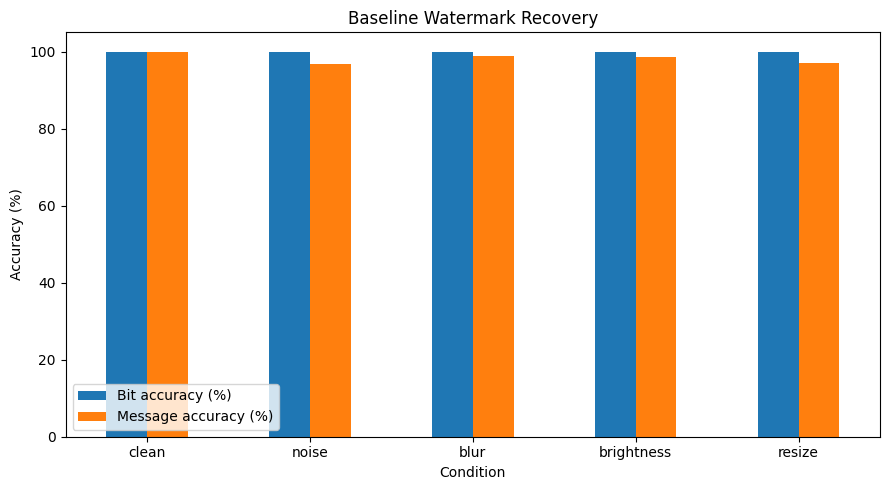

In [4]:
table1.plot(kind="bar", figsize=(9, 5))

plt.title("Baseline Watermark Recovery")
plt.xlabel("Condition")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

Figure 3 — Baseline Training Curves

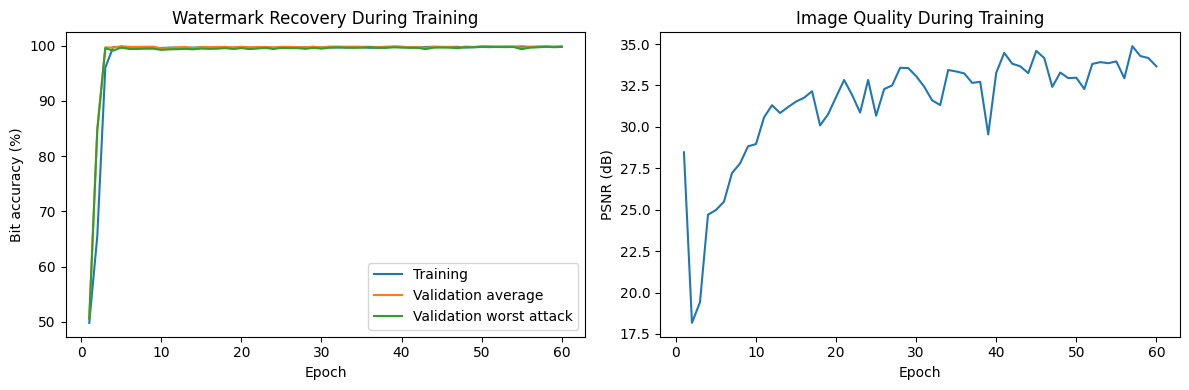

In [5]:
history = pd.read_csv("results/baseline_uniform/metrics.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history["epoch"],
    history["train_bit_acc"] * 100,
    label="Training"
)

axes[0].plot(
    history["epoch"],
    history["val_mean_attacked_bit_acc"] * 100,
    label="Validation average"
)

axes[0].plot(
    history["epoch"],
    history["val_worst_bit_acc"] * 100,
    label="Validation worst attack"
)

axes[0].set_title("Watermark Recovery During Training")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Bit accuracy (%)")
axes[0].legend()

axes[1].plot(history["epoch"], history["val_psnr"])
axes[1].set_title("Image Quality During Training")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("PSNR (dB)")

plt.tight_layout()
plt.show()

Table 2 — FGAS Attack Sampling Probabilities

In [6]:
fgas = pd.read_csv("results/fgas_update.csv")

table2 = pd.DataFrame({
    "Attack": fgas["attack"],
    "Validation bit accuracy (%)": fgas["val_bit_acc"] * 100,
    "Failure rate (%)": fgas["failure"] * 100,
    "Old probability (%)": fgas["old_prob"] * 100,
    "New probability (%)": fgas["new_prob"] * 100
})

display(table2.round(3))

,Attack,Validation bit accuracy (%),Failure rate (%),Old probability (%),New probability (%)
0,noise,99.90,0.10,25.0,23.0
1,blur,99.96,0.04,25.0,15.0
2,brightness,99.79,0.21,25.0,37.0
3,resize,99.88,0.12,25.0,25.0


The baseline recovered all hidden messages correctly from clean images. After noise, blur, brightness changes, and resizing, individual-bit accuracy remained above 99.7%, while full-message accuracy ranged from 96.75% to 98.75%. The image-quality scores were 32.97 dB PSNR and 0.9294 SSIM, indicating that the watermarked images remained similar to the originals.

The training curves show that recovery accuracy improved quickly and stayed high, while image quality generally improved as training continued.

Brightness changes caused the lowest bit accuracy, so FGAS increased their training probability from 25% to 37%. This shows that FGAS gives more practice to the model’s weakest attack. However, Experiment D still needs to be completed to determine whether this improves performance compared with uniform training.